# WEEK 9: FINAL EVALUATION AND PROJECT CLOSURE

## 1. Project Setup and Google Drive Configuration

This section imports the required libraries, mounts Google Drive, and defines the input and output directories for the final project evaluation.

The existing project results from Weeks 3, 6, 7, and 8 are reused to perform the final analysis.

A separate Week9_Results directory is created to store the final predictions, evaluation tables, graphs, visualizations, and project summary.

In [1]:
# =========================================================
# WEEK 9 - CELL 1
# PROJECT SETUP AND GOOGLE DRIVE
# =========================================================

from google.colab import drive
drive.mount("/content/drive")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display
import math

# ---------------------------------------------------------
# PROJECT DIRECTORIES
# ---------------------------------------------------------

BASE_DIR = Path(
    "/content/drive/MyDrive/ECE501_DRASHTI"
)

WEEK3_DIR = BASE_DIR / "Week3_Results"
WEEK6_DIR = BASE_DIR / "Week6_Results"
WEEK7_DIR = BASE_DIR / "Week7_Results"
WEEK8_DIR = BASE_DIR / "Week8_Results"

WEEK9_DIR = BASE_DIR / "Week9_Results"

TABLE_DIR = WEEK9_DIR / "tables"
GRAPH_DIR = WEEK9_DIR / "graphs"
VISUAL_DIR = WEEK9_DIR / "visualizations"

for folder in [TABLE_DIR, GRAPH_DIR, VISUAL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("WEEK 9 PROJECT SETUP COMPLETE")
print("--------------------------------")

print("Project directory:", BASE_DIR)
print("Week 9 output directory:", WEEK9_DIR)

print("\nOutput folders created successfully.")

Mounted at /content/drive
WEEK 9 PROJECT SETUP COMPLETE
--------------------------------
Project directory: /content/drive/MyDrive/ECE501_DRASHTI
Week 9 output directory: /content/drive/MyDrive/ECE501_DRASHTI/Week9_Results

Output folders created successfully.


## 2. Loading Previous Weeks' Results

The final evaluation uses the results generated during the earlier project stages.

The following files are loaded:

1. Week 3: Original 100-vehicle error table containing ground-truth headings and PCA, Original Hough, and Contour-Based predictions.
2. Week 7: Final 100-vehicle comparison table containing Modified Hough results.
3. Week 8: Directional heading estimation results obtained using Modified Hough and silhouette asymmetry.
4. Week 6: Vehicle crop manifest containing the image paths required for final visualizations.

The original Week 3 dataset is used as the reference to maintain the same 100 vehicle observations throughout the final evaluation.

In [2]:
# =========================================================
# WEEK 9 - CELL 2
# LOAD PREVIOUS PROJECT RESULTS
# =========================================================

W3_FILE = (
    WEEK3_DIR /
    "week3_100_image_error_table.csv"
)

W7_FILE = (
    WEEK7_DIR /
    "tables" /
    "08_final_100_vehicle_results.csv"
)

W8_FILE = (
    WEEK8_DIR /
    "tables" /
    "week8_automatic_directional_heading.csv"
)

MANIFEST_FILE = (
    WEEK6_DIR /
    "tables" /
    "01_vehicle_crop_manifest.csv"
)

# Check required files

required_files = [
    W3_FILE,
    W7_FILE,
    W8_FILE,
    MANIFEST_FILE
]

for file in required_files:

    if not file.exists():
        raise FileNotFoundError(
            f"Required file not found: {file}"
        )

# Load CSV files

week3_df = pd.read_csv(W3_FILE)
week7_df = pd.read_csv(W7_FILE)
week8_df = pd.read_csv(W8_FILE)
manifest_df = pd.read_csv(MANIFEST_FILE)

# Remove duplicate IDs only after checking
assert week3_df["Vehicle_ID"].is_unique

week3_df = week3_df.sort_values(
    "Vehicle_ID"
).reset_index(drop=True)

print("PREVIOUS RESULTS LOADED")
print("-----------------------")

print("Week 3 observations:", len(week3_df))
print("Week 7 observations:", len(week7_df))
print("Week 8 predictions:", len(week8_df))
print("Vehicle crop records:", len(manifest_df))

print("\nWeek 3 columns:")
print(week3_df.columns.tolist())

print("\nWeek 7 columns:")
print(week7_df.columns.tolist())

print("\nWeek 8 columns:")
print(week8_df.columns.tolist())

PREVIOUS RESULTS LOADED
-----------------------
Week 3 observations: 100
Week 7 observations: 100
Week 8 predictions: 100
Vehicle crop records: 100

Week 3 columns:
['Vehicle_ID', 'Image_ID', 'Vehicle_Number', 'Class_ID', 'Vehicle_Class', 'Difficulty', 'Ground_Truth_Heading_deg', 'Ground_Truth_Orientation_deg', 'PCA_Estimated_Orientation_deg', 'PCA_Angular_Error_deg', 'Hough_Estimated_Orientation_deg', 'Hough_Angular_Error_deg', 'Contour_Estimated_Orientation_deg', 'Contour_Angular_Error_deg']

Week 7 columns:
['Vehicle_ID', 'Image_ID', 'Vehicle_Number', 'Class_ID', 'Vehicle_Class', 'Difficulty', 'Ground_Truth_Heading_deg', 'Ground_Truth_Orientation_deg', 'PCA_Estimated_Orientation_deg', 'PCA_Angular_Error_deg', 'Hough_Estimated_Orientation_deg', 'Hough_Angular_Error_deg', 'Contour_Estimated_Orientation_deg', 'Contour_Angular_Error_deg', 'Crop_Path', 'Crop_Available', 'PCA_error', 'Original_Hough_Week3_error', 'Contour_error', 'Week6_Baseline', 'Modified_Hough', 'Detected_Lines', 'Sele

## 3. Consolidating Final Predictions for the 100 Vehicles

The prediction results from the earlier weeks are combined using Vehicle_ID as the common identifier.

The PCA, Original Hough Transform, Contour-Based, and Modified Hough predictions are retained using their existing 0°–90° orientation convention.

The Week 8 directional heading predictions are added separately using their 0°–359° convention.

The combined dataset retains all original 100 vehicle observations. Missing predictions are represented as NaN rather than removing the corresponding vehicles.

This ensures that the final evaluation accounts for both successful predictions and estimation failures.

In [3]:
# =========================================================
# WEEK 9 - CELL 3
# CONSOLIDATE ALL PREDICTIONS
# =========================================================

# ---------------------------------------------------------
# VALIDATE VEHICLE IDENTIFIERS
# ---------------------------------------------------------

assert len(week3_df) == 100, (
    "Expected exactly 100 original vehicles."
)

assert week3_df["Vehicle_ID"].is_unique

assert week7_df["Vehicle_ID"].is_unique
assert week8_df["Vehicle_ID"].is_unique

# ---------------------------------------------------------
# SELECT WEEK 7 MODIFIED HOUGH RESULTS
# ---------------------------------------------------------

week7_columns = [
    "Vehicle_ID",
    "Modified_Hough",
    "Modified_Hough_error"
]

for col in week7_columns:
    if col not in week7_df.columns:
        raise KeyError(
            f"Missing Week 7 column: {col}"
        )

week7_selected = week7_df[
    week7_columns
].rename(columns={
    "Modified_Hough":
        "Modified_Hough_Estimated_Orientation_deg",

    "Modified_Hough_error":
        "Modified_Hough_Error_deg"
})

# ---------------------------------------------------------
# SELECT WEEK 8 DIRECTIONAL RESULTS
# ---------------------------------------------------------

week8_columns = [
    "Vehicle_ID",
    "Estimated_Axis_deg",
    "Estimated_Directional_Heading_deg"
]

for col in week8_columns:
    if col not in week8_df.columns:
        raise KeyError(
            f"Missing Week 8 column: {col}"
        )

week8_selected = week8_df[
    week8_columns
].rename(columns={
    "Estimated_Directional_Heading_deg":
        "Week8_Estimated_Heading_deg"
})

# ---------------------------------------------------------
# MERGE ALL RESULTS
# ---------------------------------------------------------

final_df = week3_df.merge(
    week7_selected,
    on="Vehicle_ID",
    how="left",
    validate="one_to_one"
)

final_df = final_df.merge(
    week8_selected,
    on="Vehicle_ID",
    how="left",
    validate="one_to_one"
)

# ---------------------------------------------------------
# CALCULATE ORIENTATION ERRORS
# ---------------------------------------------------------

orientation_methods = {
    "PCA": "PCA_Estimated_Orientation_deg",
    "Original_Hough": "Hough_Estimated_Orientation_deg",
    "Contour": "Contour_Estimated_Orientation_deg",
    "Modified_Hough":
        "Modified_Hough_Estimated_Orientation_deg"
}

for method, prediction_column in orientation_methods.items():

    final_df[prediction_column] = pd.to_numeric(
        final_df[prediction_column],
        errors="coerce"
    )

    error_column = method + "_Error_deg"

    final_df[error_column] = (
        final_df["Ground_Truth_Orientation_deg"]
        - final_df[prediction_column]
    ).abs()

# ---------------------------------------------------------
# CALCULATE FULL DIRECTIONAL HEADING ERROR
# ---------------------------------------------------------

final_df["Week8_Estimated_Heading_deg"] = pd.to_numeric(
    final_df["Week8_Estimated_Heading_deg"],
    errors="coerce"
)

def angular_error_360(estimated, actual):

    difference = abs(estimated - actual) % 360

    return min(difference, 360 - difference)


final_df["Week8_Directional_Error_deg"] = final_df.apply(
    lambda row: angular_error_360(
        row["Week8_Estimated_Heading_deg"],
        row["Ground_Truth_Heading_deg"]
    )
    if pd.notna(row["Week8_Estimated_Heading_deg"])
    and pd.notna(row["Ground_Truth_Heading_deg"])
    else np.nan,
    axis=1
)

# ---------------------------------------------------------
# VALIDATION
# ---------------------------------------------------------

assert len(final_df) == 100
assert final_df["Vehicle_ID"].is_unique

print("FINAL PREDICTION DATASET CREATED")
print("--------------------------------")

print("Total original vehicles:", len(final_df))

print(
    "Week 8 valid predictions:",
    final_df["Week8_Estimated_Heading_deg"].notna().sum()
)

print(
    "Week 8 missing predictions:",
    final_df["Week8_Estimated_Heading_deg"].isna().sum()
)

display(final_df.head(10))

FINAL PREDICTION DATASET CREATED
--------------------------------
Total original vehicles: 100
Week 8 valid predictions: 100
Week 8 missing predictions: 0


,Vehicle_ID,Image_ID,Vehicle_Number,Class_ID,Vehicle_Class,Difficulty,Ground_Truth_Heading_deg,Ground_Truth_Orientation_deg,PCA_Estimated_Orientation_deg,PCA_Angular_Error_deg,...,Contour_Estimated_Orientation_deg,Contour_Angular_Error_deg,Modified_Hough_Estimated_Orientation_deg,Modified_Hough_Error_deg,Estimated_Axis_deg,Week8_Estimated_Heading_deg,PCA_Error_deg,Original_Hough_Error_deg,Contour_Error_deg,Week8_Directional_Error_deg
0,00XD_3rEO_4KVW_vehicle_1,00XD_3rEO_4KVW,1,7,SUV,0,49.00,49.00,54.61,5.61,...,56.71,7.71,46.306921,2.693079,49.314549,49.314549,5.61,3.86,7.71,0.314549
1,2GuW_AKSD_y8m2_vehicle_1,2GuW_AKSD_y8m2,1,5,MotorCycle,0,182.36,2.36,2.20,0.16,...,0.00,2.36,1.903204,0.456796,9.372670,9.372670,0.16,4.17,2.36,172.987330
2,2h07_apct_WjnB_vehicle_1,2h07_apct_WjnB,1,7,SUV,0,168.38,11.62,7.70,3.92,...,0.00,11.62,12.251209,0.631209,169.445736,169.445736,3.92,19.45,11.62,1.065736
3,3J2E_oL5U_TE2G_vehicle_1,3J2E_oL5U_TE2G,1,7,SUV,0,4.66,4.66,3.60,1.06,...,0.00,4.66,0.617572,4.042428,1.089514,181.089514,1.06,4.25,4.66,176.429514
4,3LzM_y7ht_SdIz_vehicle_1,3LzM_y7ht_SdIz,1,7,SUV,0,24.90,24.90,23.87,1.03,...,32.76,7.86,26.649071,1.749071,29.278397,29.278397,1.03,2.56,7.86,4.378397
5,4AYY_W6bt_vwi6_vehicle_1,4AYY_W6bt_vwi6,1,1,AutoRicksaw,0,180.00,0.00,20.51,20.51,...,35.27,35.27,2.998736,2.998736,174.979892,174.979892,20.51,12.10,35.27,5.020108
6,5N3r_jiDF_1pzt_vehicle_1,5N3r_jiDF_1pzt,1,7,SUV,0,175.14,4.86,6.86,2.00,...,4.33,0.53,6.516875,1.656875,173.483125,173.483125,2.00,1.10,0.53,1.656875
7,5QtK_2GHz_wRDq_vehicle_1,5QtK_2GHz_wRDq,1,7,SUV,0,11.00,11.00,19.42,8.42,...,3.58,7.42,45.000151,34.000151,133.617116,133.617116,8.42,8.68,7.42,122.617116
8,6JBU_iCb9_Lszd_vehicle_1,6JBU_iCb9_Lszd,1,12,Truck,0,191.00,11.00,3.98,7.02,...,0.00,11.00,1.373197,9.626803,6.957049,186.957049,7.02,2.99,11.00,4.042951
9,6TWc_P2qX_R4VI_vehicle_1,6TWc_P2qX_R4VI,1,5,MotorCycle,0,357.70,2.30,4.68,2.38,...,0.00,2.30,16.106670,13.806670,167.862717,167.862717,2.38,2.60,2.30,170.162717


## 4. Final Directional Heading Evaluation (0°–359°)

The directional heading estimates generated in Week 8 are evaluated against the original ground-truth heading annotations.

The shortest circular angular difference is used to calculate the directional heading error.

The following performance metrics are calculated:

- Total number of vehicle samples.
- Number of successful predictions.
- Number of failed predictions.
- Prediction success rate.
- Mean Absolute Angular Error (MAE).
- Median Angular Error.
- Maximum Angular Error.
- Standard Deviation of Angular Error.
- Number of vehicles with errors greater than or equal to 30°.

The evaluation uses only successfully generated directional predictions when calculating the error statistics. Failed predictions are separately included in the success-rate calculation.

In [4]:
# =========================================================
# WEEK 9 - CELL 4
# FINAL DIRECTIONAL HEADING EVALUATION
# =========================================================

directional_errors = final_df[
    "Week8_Directional_Error_deg"
].dropna()

total_vehicles = len(final_df)

successful = len(directional_errors)

failed = total_vehicles - successful

success_rate = (
    successful / total_vehicles * 100
    if total_vehicles > 0 else 0
)

directional_summary = pd.DataFrame([{

    "Total_Vehicles": total_vehicles,

    "Successful_Predictions": successful,

    "Failed_Predictions": failed,

    "Success_Rate_%": success_rate,

    "MAE_deg": directional_errors.mean(),

    "Median_Error_deg": directional_errors.median(),

    "Maximum_Error_deg": directional_errors.max(),

    "Standard_Deviation_deg": directional_errors.std(),

    "Errors_Above_30_deg": (
        directional_errors >= 30
    ).sum()

}])

print("FINAL DIRECTIONAL HEADING PERFORMANCE")
print("--------------------------------------")

display(
    directional_summary.round(2)
)

print("\nDirectional heading error statistics:")

print("MAE:", round(directional_errors.mean(), 2))

print("Median:", round(directional_errors.median(), 2))

print("Maximum:", round(directional_errors.max(), 2))

print("Successful:", successful)

print("Failed:", failed)

print("Success rate:", round(success_rate, 2), "%")

FINAL DIRECTIONAL HEADING PERFORMANCE
--------------------------------------


,Total_Vehicles,Successful_Predictions,Failed_Predictions,Success_Rate_%,MAE_deg,Median_Error_deg,Maximum_Error_deg,Standard_Deviation_deg,Errors_Above_30_deg
0,100,100,0,100.0,82.02,13.35,179.91,82.83,48



Directional heading error statistics:
MAE: 82.02
Median: 13.35
Maximum: 179.91
Successful: 100
Failed: 0
Success rate: 100.0 %


## 5. Comparative Evaluation of Orientation Estimation Methods

The performance of the earlier orientation estimation methods is compared using their original 0°–90° orientation convention.

The methods included are:

1. Principal Component Analysis (PCA).
2. Original Hough Transform.
3. Contour-Based Orientation Estimation.
4. Modified Hough Transform.

The same ground-truth orientation annotations and original 100 vehicle observations are used for all methods.

The following metrics are calculated:

- Total vehicles.
- Successful predictions.
- Failed predictions.
- Success rate.
- Mean Angular Error.
- Median Angular Error.
- Maximum Angular Error.
- Standard Deviation.
- Number of high-error predictions (≥30°).

The comparison identifies the relative performance of the four methods and evaluates the improvement obtained through the Modified Hough Transform.

In [5]:
# =========================================================
# WEEK 9 - CELL 5
# ORIENTATION METHOD COMPARISON
# =========================================================

method_error_columns = {
    "PCA": "PCA_Error_deg",
    "Original Hough": "Original_Hough_Error_deg",
    "Contour-Based": "Contour_Error_deg",
    "Modified Hough": "Modified_Hough_Error_deg"
}

comparison_rows = []

for method, error_column in method_error_columns.items():

    errors = final_df[error_column].dropna()

    total = len(final_df)

    valid = len(errors)

    comparison_rows.append({

        "Method": method,

        "Total_Vehicles": total,

        "Successful_Predictions": valid,

        "Failed_Predictions": total - valid,

        "Success_Rate_%": valid / total * 100,

        "MAE_deg": errors.mean(),

        "Median_Error_deg": errors.median(),

        "Maximum_Error_deg": errors.max(),

        "Standard_Deviation_deg": errors.std(),

        "High_Error_Count_30deg": (
            errors >= 30
        ).sum()
    })


comparison_df = pd.DataFrame(comparison_rows)

print("ORIENTATION METHOD COMPARISON")
print("-----------------------------")

display(
    comparison_df.round(2)
)

best_method = comparison_df.loc[
    comparison_df["MAE_deg"].idxmin()
]

print("\nLOWEST MAE METHOD")
print("-----------------")

print("Method:", best_method["Method"])

print(
    "Mean Angular Error:",
    round(best_method["MAE_deg"], 2),
    "degrees"
)

ORIENTATION METHOD COMPARISON
-----------------------------


,Method,Total_Vehicles,Successful_Predictions,Failed_Predictions,Success_Rate_%,MAE_deg,Median_Error_deg,Maximum_Error_deg,Standard_Deviation_deg,High_Error_Count_30deg
0,PCA,100,100,0,100.0,10.74,4.85,81.71,16.11,8
1,Original Hough,100,98,2,98.0,12.46,4.18,82.39,20.44,11
2,Contour-Based,100,100,0,100.0,10.97,5.72,89.00,16.44,12
3,Modified Hough,100,100,0,100.0,5.35,2.02,84.94,11.12,3



LOWEST MAE METHOD
-----------------
Method: Modified Hough
Mean Angular Error: 5.35 degrees


## 6. Class-wise Comparative Analysis

The orientation estimation methods are further evaluated across different vehicle classes.

The mean angular error, median angular error, and number of valid predictions are calculated separately for each vehicle class.

This analysis helps determine whether certain vehicle categories are more difficult to process using conventional image-processing techniques.

The results are used to identify class-dependent performance variations and potential limitations of the estimation methods.

In [6]:
# =========================================================
# WEEK 9 - CELL 6
# CLASS-WISE METHOD COMPARISON
# =========================================================

class_results = []

for vehicle_class, group in final_df.groupby(
    "Vehicle_Class",
    dropna=False
):

    for method, error_column in method_error_columns.items():

        errors = group[error_column].dropna()

        class_results.append({

            "Vehicle_Class": vehicle_class,

            "Method": method,

            "Total_Samples": len(group),

            "Valid_Predictions": len(errors),

            "Mean_Error_deg": errors.mean(),

            "Median_Error_deg": errors.median(),

            "Maximum_Error_deg": errors.max()
        })


classwise_df = pd.DataFrame(class_results)

print("CLASS-WISE COMPARISON")
print("---------------------")

display(
    classwise_df.round(2)
)

print("\nHighest class-method mean errors:")

display(
    classwise_df.sort_values(
        "Mean_Error_deg",
        ascending=False
    ).head(10)
)

CLASS-WISE COMPARISON
---------------------


,Vehicle_Class,Method,Total_Samples,Valid_Predictions,Mean_Error_deg,Median_Error_deg,Maximum_Error_deg
0,Auto3WCargo,PCA,3,3,11.34,4.15,29.13
1,Auto3WCargo,Original Hough,3,3,38.58,19.98,81.49
2,Auto3WCargo,Contour-Based,3,3,13.41,4.43,34.74
3,Auto3WCargo,Modified Hough,3,3,5.06,3.53,8.12
4,AutoRicksaw,PCA,8,8,7.49,5.36,20.51
5,AutoRicksaw,Original Hough,8,8,13.97,8.07,63.49
6,AutoRicksaw,Contour-Based,8,8,8.29,3.06,35.27
7,AutoRicksaw,Modified Hough,8,8,4.77,2.57,15.84
8,Bus,PCA,2,2,27.32,27.32,52.71
9,Bus,Original Hough,2,2,0.73,0.73,1.01



Highest class-method mean errors:


,Vehicle_Class,Method,Total_Samples,Valid_Predictions,Mean_Error_deg,Median_Error_deg,Maximum_Error_deg
13,Container,Original Hough,3,2,49.130000,49.130,77.16
12,Container,PCA,3,3,40.116667,42.070,43.61
1,Auto3WCargo,Original Hough,3,3,38.583333,19.980,81.49
37,Trailer,Original Hough,3,3,32.866667,8.910,82.39
38,Trailer,Contour-Based,3,3,30.210000,0.820,89.00
36,Trailer,PCA,3,3,28.966667,4.070,81.71
14,Container,Contour-Based,3,3,27.486667,34.100,42.36
8,Bus,PCA,2,2,27.315000,27.315,52.71
10,Bus,Contour-Based,2,2,24.180000,24.180,45.18
28,Sedan,PCA,7,7,23.548571,25.920,72.90


## 7. Identification of Major Directional Heading Errors

The directional heading predictions are sorted according to their angular errors.

The highest-error vehicle samples are identified for further investigation.

This section examines cases where the estimated heading differs significantly from the ground-truth heading.

Special attention is given to errors approaching 180°, which may indicate that the estimated direction is opposite to the actual vehicle direction.

The results provide a basis for understanding the limitations of the silhouette-asymmetry-based directional estimation method.

In [7]:
# =========================================================
# WEEK 9 - CELL 7
# MAJOR DIRECTIONAL ERROR ANALYSIS
# =========================================================

valid_directional = final_df.dropna(
    subset=["Week8_Directional_Error_deg"]
).copy()

valid_directional = valid_directional.sort_values(
    "Week8_Directional_Error_deg",
    ascending=False
)

top_errors = valid_directional.head(15)

print("TOP 15 DIRECTIONAL HEADING ERRORS")
print("---------------------------------")

display(
    top_errors[
        [
            "Vehicle_ID",
            "Vehicle_Class",
            "Ground_Truth_Heading_deg",
            "Week8_Estimated_Heading_deg",
            "Week8_Directional_Error_deg"
        ]
    ].round(2)
)

# Identify errors close to 180 degrees

opposite_direction_cases = valid_directional[
    valid_directional["Week8_Directional_Error_deg"] >= 150
]

print("\nPotential opposite-direction errors (>=150 degrees):")

display(
    opposite_direction_cases[
        [
            "Vehicle_ID",
            "Ground_Truth_Heading_deg",
            "Week8_Estimated_Heading_deg",
            "Week8_Directional_Error_deg"
        ]
    ].round(2)
)

# Save top error table

top_errors[
    [
        "Vehicle_ID",
        "Vehicle_Class",
        "Ground_Truth_Heading_deg",
        "Week8_Estimated_Heading_deg",
        "Week8_Directional_Error_deg"
    ]
].to_csv(
    TABLE_DIR / "05_top_directional_errors.csv",
    index=False
)

TOP 15 DIRECTIONAL HEADING ERRORS
---------------------------------


,Vehicle_ID,Vehicle_Class,Ground_Truth_Heading_deg,Week8_Estimated_Heading_deg,Week8_Directional_Error_deg
36,OyGP_UjOQ_hJIP_vehicle_1,Bus,86.00,266.09,179.91
50,ZKIx_Msfo_O7V9_vehicle_1,SUV,356.78,177.02,179.76
47,WB91_YzXz_82r4_vehicle_1,Container,1.00,181.36,179.64
96,y0bo_oHBY_y2mz_vehicle_1,Container,6.00,185.51,179.51
49,Yfx3_zEFB_Ld6Y_vehicle_1,SUV,350.48,171.25,179.23
99,zarI_WVuj_0DCc_vehicle_1,Container,6.00,185.18,179.18
13,9SAd_tJKX_KWb9_vehicle_1,SUV,184.66,3.18,178.52
17,Df3T_rTNG_KSCM_vehicle_1,MotorCycle,173.64,351.82,178.18
33,ON14_goh0_iF0V_vehicle_1,SUV,183.74,5.74,178.00
66,hwun_OlDq_ey5G_vehicle_1,Auto3WCargo,270.00,92.02,177.98



Potential opposite-direction errors (>=150 degrees):


,Vehicle_ID,Ground_Truth_Heading_deg,Week8_Estimated_Heading_deg,Week8_Directional_Error_deg
36,OyGP_UjOQ_hJIP_vehicle_1,86.00,266.09,179.91
50,ZKIx_Msfo_O7V9_vehicle_1,356.78,177.02,179.76
47,WB91_YzXz_82r4_vehicle_1,1.00,181.36,179.64
96,y0bo_oHBY_y2mz_vehicle_1,6.00,185.51,179.51
49,Yfx3_zEFB_Ld6Y_vehicle_1,350.48,171.25,179.23
99,zarI_WVuj_0DCc_vehicle_1,6.00,185.18,179.18
13,9SAd_tJKX_KWb9_vehicle_1,184.66,3.18,178.52
17,Df3T_rTNG_KSCM_vehicle_1,173.64,351.82,178.18
33,ON14_goh0_iF0V_vehicle_1,183.74,5.74,178.00
66,hwun_OlDq_ey5G_vehicle_1,270.00,92.02,177.98


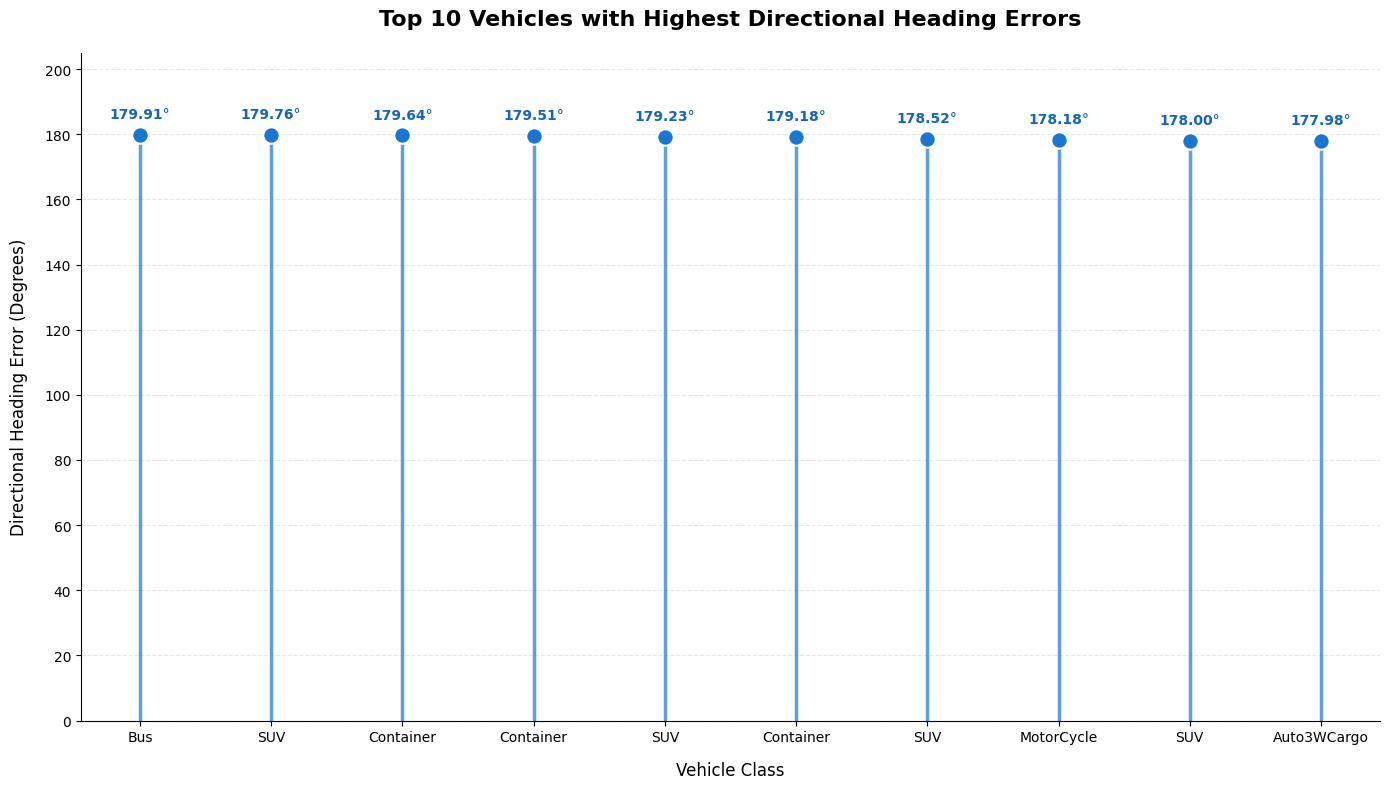

TOP 10 VEHICLES WITH HIGHEST DIRECTIONAL HEADING ERRORS


,Vehicle_Class,Vehicle_ID,Ground_Truth_Heading_deg,Week8_Estimated_Heading_deg,Week8_Directional_Error_deg
36,Bus,OyGP_UjOQ_hJIP_vehicle_1,86.00,266.09,179.91
50,SUV,ZKIx_Msfo_O7V9_vehicle_1,356.78,177.02,179.76
47,Container,WB91_YzXz_82r4_vehicle_1,1.00,181.36,179.64
96,Container,y0bo_oHBY_y2mz_vehicle_1,6.00,185.51,179.51
49,SUV,Yfx3_zEFB_Ld6Y_vehicle_1,350.48,171.25,179.23
99,Container,zarI_WVuj_0DCc_vehicle_1,6.00,185.18,179.18
13,SUV,9SAd_tJKX_KWb9_vehicle_1,184.66,3.18,178.52
17,MotorCycle,Df3T_rTNG_KSCM_vehicle_1,173.64,351.82,178.18
33,SUV,ON14_goh0_iF0V_vehicle_1,183.74,5.74,178.00
66,Auto3WCargo,hwun_OlDq_ey5G_vehicle_1,270.00,92.02,177.98


CSV table saved successfully at: /content/drive/MyDrive/ECE501_DRASHTI/Week9_Results/tables/05_top_10_directional_heading_errors.csv


In [21]:

# =========================================================
# TOP 10 VEHICLES WITH HIGHEST DIRECTIONAL HEADING ERRORS
# BLUE LOLLIPOP CHART
# =========================================================

top_10_errors = valid_directional.nlargest(
    10, "Week8_Directional_Error_deg"
).copy()

# Sort by error (highest first)
top_10_errors = top_10_errors.sort_values(
    "Week8_Directional_Error_deg",
    ascending=False
)

# Use only vehicle class names on X-axis
labels = top_10_errors["Vehicle_Class"].astype(str)

errors = top_10_errors["Week8_Directional_Error_deg"]

# Create figure
fig, ax = plt.subplots(figsize=(14, 8))

x_positions = range(len(errors))

# Vertical stems
ax.vlines(
    x_positions,
    0,
    errors,
    color="#1976D2",
    linewidth=2.5,
    alpha=0.7
)

# Blue circular markers
ax.scatter(
    x_positions,
    errors,
    color="#1976D2",
    s=140,
    edgecolors="white",
    linewidths=1.5,
    zorder=3
)

# Display error values above markers
for i, value in enumerate(errors):

    ax.annotate(
        f"{value:.2f}°",
        (i, value),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color="#1565C0"
    )

# X-axis labels
ax.set_xticks(list(x_positions))
ax.set_xticklabels(
    labels,
    rotation=0,
    ha="center",
    fontsize=10
)

# Axis limits and ticks
ax.set_ylim(0, 205)
ax.set_yticks(range(0, 201, 20))

# Axis titles
ax.set_xlabel(
    "Vehicle Class",
    fontsize=12,
    labelpad=12
)

ax.set_ylabel(
    "Directional Heading Error (Degrees)",
    fontsize=12,
    labelpad=12
)

# Graph title
ax.set_title(
    "Top 10 Vehicles with Highest Directional Heading Errors",
    fontsize=16,
    fontweight="bold",
    pad=20
)

# Grid
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# Clean appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save graph
plt.savefig(
    GRAPH_DIR / "05_top_10_directional_heading_errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display top 10 results
print("TOP 10 VEHICLES WITH HIGHEST DIRECTIONAL HEADING ERRORS")

display(
    top_10_errors[
        [
            "Vehicle_Class",
            "Vehicle_ID",
            "Ground_Truth_Heading_deg",
            "Week8_Estimated_Heading_deg",
            "Week8_Directional_Error_deg"
        ]
    ].round(2)
)
# Save Top 10 results as CSV
csv_path = TABLE_DIR / "05_top_10_directional_heading_errors.csv"

top_10_errors[
    [
        "Vehicle_Class",
        "Vehicle_ID",
        "Ground_Truth_Heading_deg",
        "Week8_Estimated_Heading_deg",
        "Week8_Directional_Error_deg"
    ]
].round(2).to_csv(csv_path, index=False)

print(f"CSV table saved successfully at: {csv_path}")

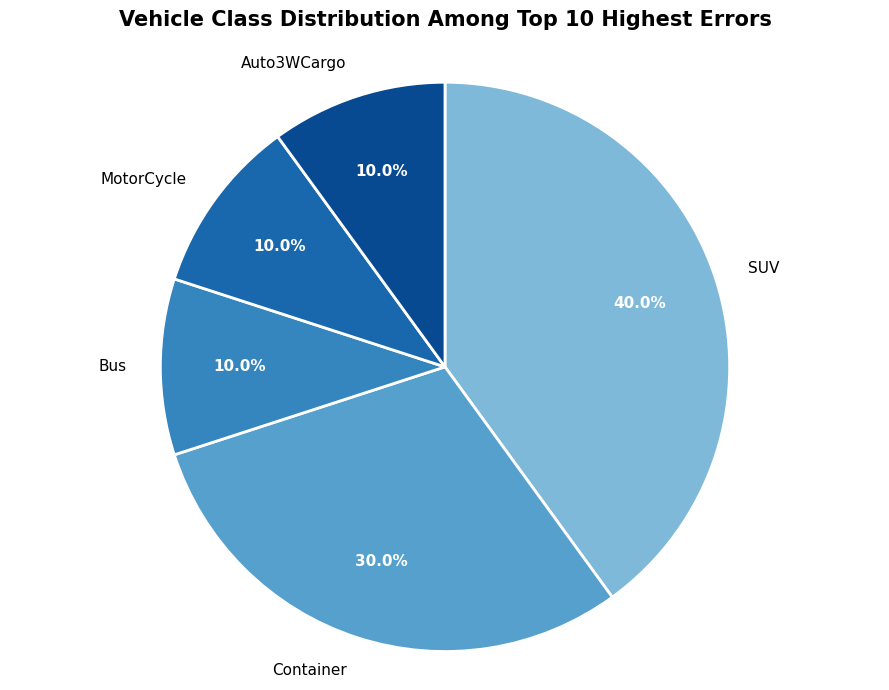

VEHICLE CLASS DISTRIBUTION IN TOP 10


,Vehicle_Class,Number_of_Vehicles
0,SUV,4
1,Container,3
2,Bus,1
3,MotorCycle,1
4,Auto3WCargo,1


In [19]:

# =========================================================
# VEHICLE CLASS DISTRIBUTION - TOP 10 HIGHEST ERRORS
# =========================================================

# Count vehicles in each class
class_counts = top_10_errors["Vehicle_Class"].value_counts()

# Create pie chart
fig, ax = plt.subplots(figsize=(9, 7))

wedges, texts, autotexts = ax.pie(
    class_counts,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    pctdistance=0.72,
    labeldistance=1.12,
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 2
    },
    textprops={
        "fontsize": 11
    }
)

# Blue colour palette
blue_shades = plt.cm.Blues(
    [0.45 + i * 0.45 / max(len(class_counts) - 1, 1)
     for i in range(len(class_counts))]
)

for wedge, color in zip(wedges, blue_shades):
    wedge.set_facecolor(color)

# Percentage labels
for autotext in autotexts:
    autotext.set_color("white")
    autotext.set_fontweight("bold")
    autotext.set_fontsize(11)

ax.set_title(
    "Vehicle Class Distribution Among Top 10 Highest Errors",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.axis("equal")

plt.tight_layout()

# Save pie chart
plt.savefig(
    GRAPH_DIR / "06_top_10_vehicle_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display class counts
print("VEHICLE CLASS DISTRIBUTION IN TOP 10")

display(
    class_counts.reset_index().rename(
        columns={
            "index": "Vehicle_Class",
            "count": "Number_of_Vehicles"
        }
    )
)


## 8. Analysis of Failed Predictions

This section identifies vehicle samples for which the directional heading estimation pipeline did not produce a valid prediction.

Failed predictions may result from unsuccessful axis estimation, poor edge detection, unreliable silhouette extraction, or other image-processing limitations.

The failed vehicle IDs are retained for documentation and further investigation.

The success rate is reported separately from angular accuracy to ensure that the final evaluation does not overlook unsuccessful samples.

In [8]:
# =========================================================
# WEEK 9 - CELL 8
# FAILED PREDICTION ANALYSIS
# =========================================================

failed_predictions = final_df[
    final_df["Week8_Estimated_Heading_deg"].isna()
].copy()

print("FAILED DIRECTIONAL PREDICTIONS")
print("-----------------------------")

print("Number of failed predictions:", len(failed_predictions))

print("\nFailed vehicle IDs:")

display(
    failed_predictions[
        [
            "Vehicle_ID",
            "Vehicle_Class",
            "Ground_Truth_Heading_deg"
        ]
    ]
)

failed_predictions[
    [
        "Vehicle_ID",
        "Vehicle_Class",
        "Ground_Truth_Heading_deg"
    ]
].to_csv(
    TABLE_DIR / "06_prediction_failures.csv",
    index=False
)

FAILED DIRECTIONAL PREDICTIONS
-----------------------------
Number of failed predictions: 0

Failed vehicle IDs:


,Vehicle_ID,Vehicle_Class,Ground_Truth_Heading_deg


## 9. Directional Heading Error Distribution

A histogram is generated to visualize the distribution of directional angular errors across all successfully processed vehicles.

The visualization provides an overview of the accuracy and consistency of the Week 8 directional heading estimation method.

The distribution helps identify whether most predictions have relatively small errors or whether a considerable number of vehicles exhibit large directional deviations.

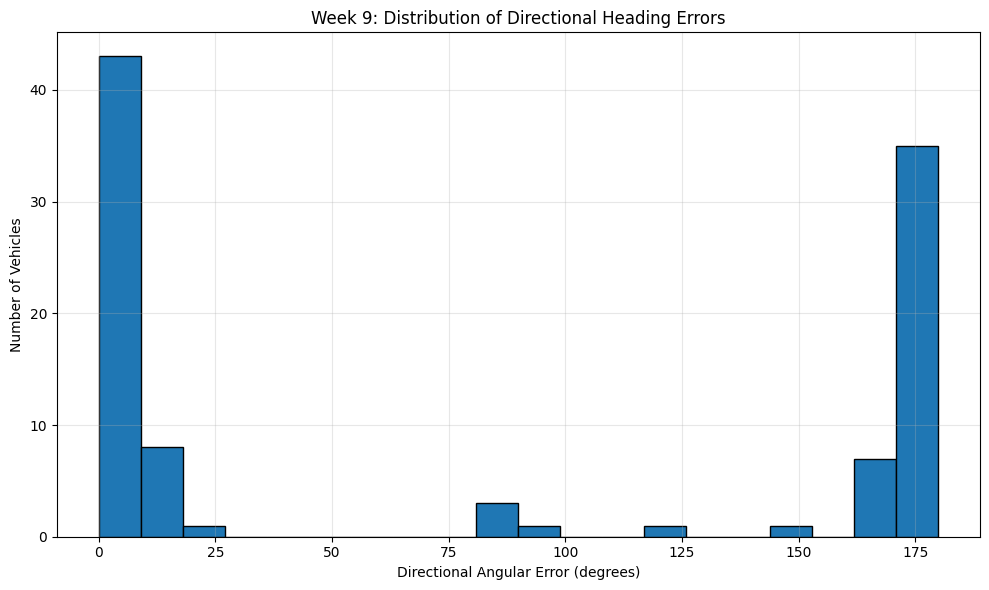

In [9]:
# =========================================================
# WEEK 9 - CELL 9
# DIRECTIONAL ERROR DISTRIBUTION
# =========================================================

plt.figure(figsize=(10, 6))

plt.hist(
    directional_errors,
    bins=20,
    edgecolor="black"
)

plt.xlabel("Directional Angular Error (degrees)")
plt.ylabel("Number of Vehicles")

plt.title(
    "Week 9: Distribution of Directional Heading Errors"
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "01_directional_error_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. Graphical Comparison of Orientation Estimation Methods

A comparative bar chart is generated to visualize the mean angular error of PCA, Original Hough Transform, Contour-Based Estimation, and Modified Hough Transform.

All four methods use the same 0°–90° orientation convention.

The comparison provides a visual representation of the relative performance of the methods and the effectiveness of the Modified Hough Transform.

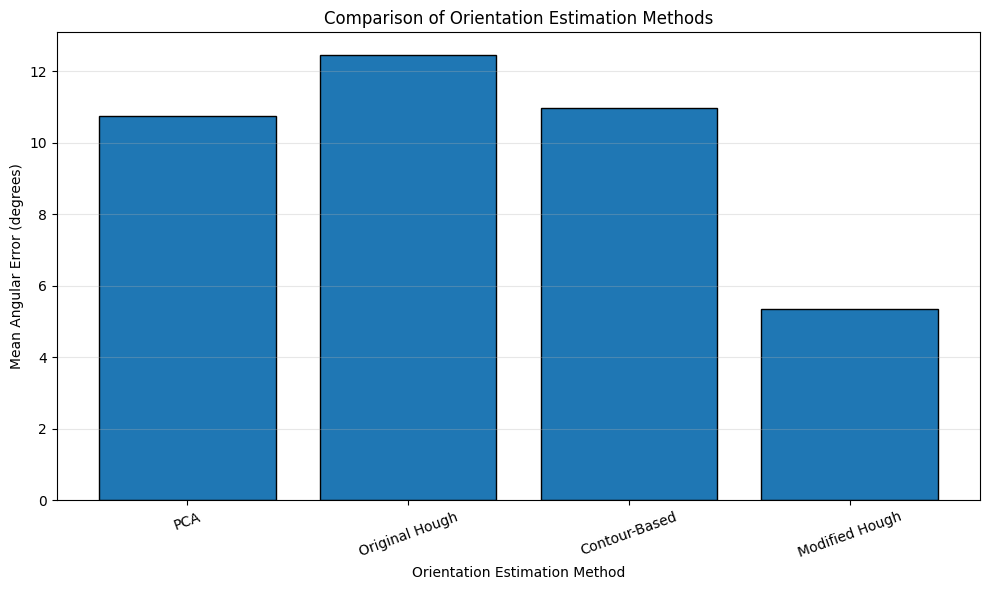

In [10]:
# =========================================================
# WEEK 9 - CELL 10
# OVERALL METHOD COMPARISON GRAPH
# =========================================================

plt.figure(figsize=(10, 6))

plot_data = comparison_df.dropna(
    subset=["MAE_deg"]
)

plt.bar(
    plot_data["Method"],
    plot_data["MAE_deg"],
    edgecolor="black"
)

plt.xlabel("Orientation Estimation Method")

plt.ylabel("Mean Angular Error (degrees)")

plt.title(
    "Comparison of Orientation Estimation Methods"
)

plt.xticks(rotation=20)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "02_orientation_method_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Class-wise Performance Visualization

A grouped bar chart is generated to compare the mean angular errors of the four orientation estimation methods across different vehicle classes.

This visualization helps identify vehicle categories where the estimation methods perform relatively well or exhibit higher errors.

The class-wise comparison complements the overall performance evaluation by highlighting variations in estimation accuracy across vehicle categories.

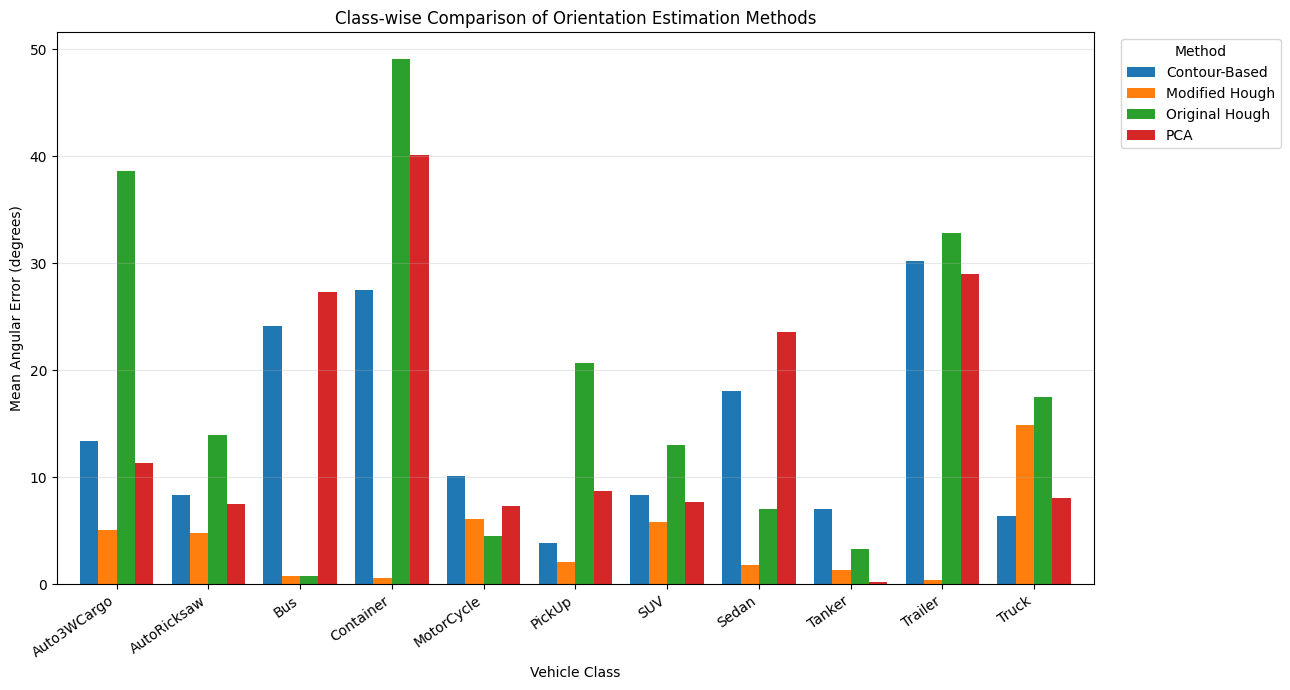

In [11]:
# =========================================================
# WEEK 9 - CELL 11
# CLASS-WISE COMPARISON GRAPH
# =========================================================

class_plot = classwise_df.pivot(
    index="Vehicle_Class",
    columns="Method",
    values="Mean_Error_deg"
)

ax = class_plot.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.8
)

ax.set_xlabel("Vehicle Class")
ax.set_ylabel("Mean Angular Error (degrees)")

ax.set_title(
    "Class-wise Comparison of Orientation Estimation Methods"
)

plt.xticks(rotation=35, ha="right")

plt.grid(axis="y", alpha=0.3)

plt.legend(
    title="Method",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "03_classwise_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 12. Ground-Truth and Estimated Directional Heading Comparison

A scatter plot is generated to compare the ground-truth directional headings with the estimated headings produced by the Week 8 method.

The horizontal axis represents the ground-truth heading, while the vertical axis represents the estimated directional heading.

An ideal prediction would lie close to the reference diagonal, indicating agreement between the estimated and ground-truth headings.

The plot provides a visual assessment of the directional estimation performance across the full 0°–359° heading range.

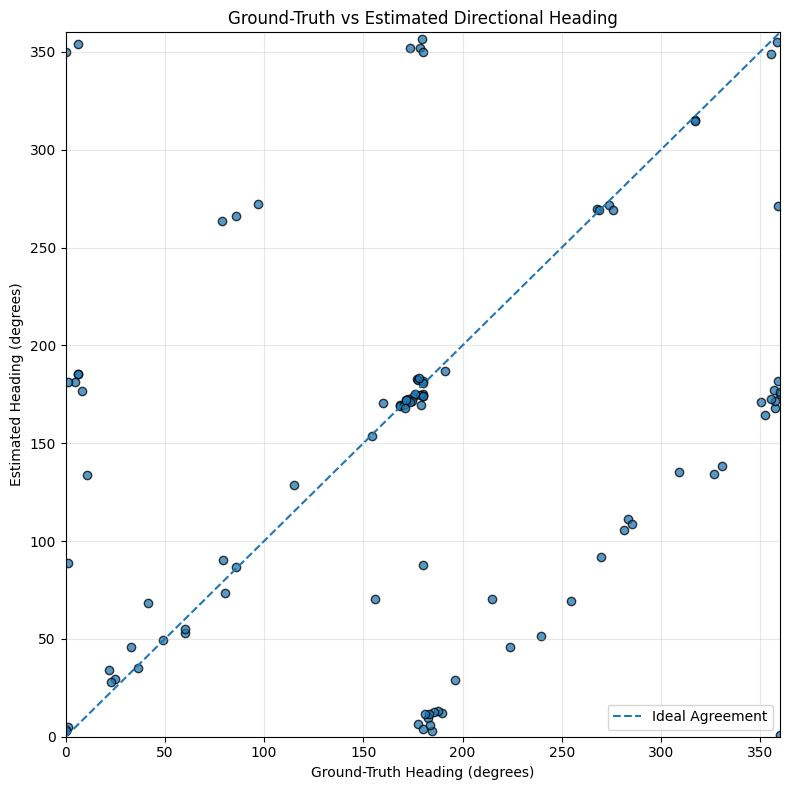

In [12]:
# =========================================================
# WEEK 9 - CELL 12
# GROUND TRUTH VS ESTIMATED HEADING
# =========================================================

plot_heading = final_df.dropna(
    subset=[
        "Ground_Truth_Heading_deg",
        "Week8_Estimated_Heading_deg"
    ]
)

plt.figure(figsize=(8, 8))

plt.scatter(
    plot_heading["Ground_Truth_Heading_deg"],
    plot_heading["Week8_Estimated_Heading_deg"],
    alpha=0.75,
    edgecolors="black"
)

plt.plot(
    [0, 360],
    [0, 360],
    linestyle="--",
    label="Ideal Agreement"
)

plt.xlim(0, 360)
plt.ylim(0, 360)

plt.xlabel("Ground-Truth Heading (degrees)")
plt.ylabel("Estimated Heading (degrees)")

plt.title(
    "Ground-Truth vs Estimated Directional Heading"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "04_directional_heading_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 13. Visual Inspection of Directional Heading Predictions

The directional heading predictions are visualized on the original vehicle crops.

For each successfully processed vehicle:

- The green arrow represents the estimated directional heading.
- The red arrow represents the ground-truth directional heading.
- The vehicle ID, ground-truth heading, estimated heading, and angular error are displayed.

The visualizations are generated in batches of 20 images to reduce memory usage and avoid Google Colab session crashes.

This provides a qualitative assessment of the directional heading estimation method across the available vehicle samples.

In [13]:
# =========================================================
# WEEK 9 - CELL 13
# VISUALIZE ALL DIRECTIONAL PREDICTIONS
# =========================================================

from math import radians, cos, sin

COLUMNS = 5
BATCH_SIZE = 20

# Map vehicle IDs to crop paths
crop_lookup = manifest_df.drop_duplicates(
    "Vehicle_ID"
).set_index("Vehicle_ID")["Crop_Path"].to_dict()


def resolve_crop_path(path_value):

    if pd.isna(path_value):
        return None

    path = Path(str(path_value))

    if path.exists():
        return path

    alternative = WEEK6_DIR / "vehicle_crops" / path.name

    if alternative.exists():
        return alternative

    return None


def draw_heading_arrow(image, heading, color):

    height, width = image.shape[:2]

    center = (width // 2, height // 2)

    length = min(width, height) * 0.4

    angle = radians(float(heading))

    endpoint = (
        int(center[0] + length * cos(angle)),
        int(center[1] + length * sin(angle))
    )

    cv2.arrowedLine(
        image,
        center,
        endpoint,
        color,
        2,
        tipLength=0.15
    )

    return image


visual_df = final_df.dropna(
    subset=[
        "Week8_Estimated_Heading_deg",
        "Ground_Truth_Heading_deg"
    ]
).copy().reset_index(drop=True)


print("Vehicles available for visualization:", len(visual_df))


for start in range(0, len(visual_df), BATCH_SIZE):

    batch = visual_df.iloc[
        start:start + BATCH_SIZE
    ]

    rows = math.ceil(len(batch) / COLUMNS)

    fig, axes = plt.subplots(
        rows,
        COLUMNS,
        figsize=(20, rows * 4)
    )

    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for i, (_, row) in enumerate(batch.iterrows()):

        vehicle_id = row["Vehicle_ID"]

        crop_path = resolve_crop_path(
            crop_lookup.get(vehicle_id)
        )

        if crop_path is None:
            continue

        image = cv2.imread(str(crop_path))

        if image is None:
            continue

        image = image.copy()

        # Green: estimated heading
        draw_heading_arrow(
            image,
            row["Week8_Estimated_Heading_deg"],
            (0, 255, 0)
        )

        # Red: ground-truth heading
        draw_heading_arrow(
            image,
            row["Ground_Truth_Heading_deg"],
            (0, 0, 255)
        )

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        axes[i].imshow(image)

        axes[i].set_title(
            f"{vehicle_id}\n"
            f"GT: {row['Ground_Truth_Heading_deg']:.1f}° | "
            f"Est: {row['Week8_Estimated_Heading_deg']:.1f}°\n"
            f"Error: {row['Week8_Directional_Error_deg']:.1f}°",
            fontsize=8
        )

    batch_number = start // BATCH_SIZE + 1

    output_path = (
        VISUAL_DIR /
        f"directional_heading_batch_{batch_number}.png"
    )

    plt.tight_layout()

    fig.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.close(fig)

    print("Saved:", output_path)


print("\nAll visualization batches completed.")

Vehicles available for visualization: 100
Saved: /content/drive/MyDrive/ECE501_DRASHTI/Week9_Results/visualizations/directional_heading_batch_1.png
Saved: /content/drive/MyDrive/ECE501_DRASHTI/Week9_Results/visualizations/directional_heading_batch_2.png
Saved: /content/drive/MyDrive/ECE501_DRASHTI/Week9_Results/visualizations/directional_heading_batch_3.png
Saved: /content/drive/MyDrive/ECE501_DRASHTI/Week9_Results/visualizations/directional_heading_batch_4.png
Saved: /content/drive/MyDrive/ECE501_DRASHTI/Week9_Results/visualizations/directional_heading_batch_5.png

All visualization batches completed.


## 14. Saving Final Project Results

All final evaluation results are organized and saved in the Week9_Results directory in Google Drive.

The following outputs are saved:

1. Final predictions and angular errors for all 100 vehicle observations.
2. Overall directional heading performance summary.
3. Comparative evaluation of the four orientation estimation methods.
4. Class-wise comparative performance results.
5. Top directional heading error cases.
6. Failed directional prediction records.

The generated graphs and vehicle visualizations are also retained in their respective output directories.

This section ensures that the final experimental results are preserved and available for project reporting and documentation.

In [14]:
# =========================================================
# WEEK 9 - CELL 14
# SAVE FINAL TABLES
# =========================================================

# ---------------------------------------------------------
# 1. FINAL 100 VEHICLE PREDICTIONS
# ---------------------------------------------------------

final_df.to_csv(
    TABLE_DIR / "01_final_100_vehicle_predictions.csv",
    index=False
)

# ---------------------------------------------------------
# 2. DIRECTIONAL HEADING SUMMARY
# ---------------------------------------------------------

directional_summary.to_csv(
    TABLE_DIR / "02_directional_heading_summary.csv",
    index=False
)

# ---------------------------------------------------------
# 3. ORIENTATION METHOD COMPARISON
# ---------------------------------------------------------

comparison_df.to_csv(
    TABLE_DIR / "03_orientation_method_comparison.csv",
    index=False
)

# ---------------------------------------------------------
# 4. CLASS-WISE COMPARISON
# ---------------------------------------------------------

classwise_df.to_csv(
    TABLE_DIR / "04_classwise_comparison.csv",
    index=False
)

# ---------------------------------------------------------
# 5. TOP DIRECTIONAL ERRORS
# ---------------------------------------------------------

top_errors[
    [
        "Vehicle_ID",
        "Vehicle_Class",
        "Ground_Truth_Heading_deg",
        "Week8_Estimated_Heading_deg",
        "Week8_Directional_Error_deg"
    ]
].to_csv(
    TABLE_DIR / "05_top_directional_errors.csv",
    index=False
)

# ---------------------------------------------------------
# 6. FAILED PREDICTIONS
# ---------------------------------------------------------

failed_predictions[
    [
        "Vehicle_ID",
        "Vehicle_Class",
        "Ground_Truth_Heading_deg"
    ]
].to_csv(
    TABLE_DIR / "06_prediction_failures.csv",
    index=False
)

# ---------------------------------------------------------
# 7. FINAL PROJECT SUMMARY TABLE
# ---------------------------------------------------------

summary_rows = []

for _, row in comparison_df.iterrows():

    summary_rows.append({

        "Evaluation": "Undirected Orientation",

        "Method": row["Method"],

        "Total_Vehicles": row["Total_Vehicles"],

        "Successful": row["Successful_Predictions"],

        "Failed": row["Failed_Predictions"],

        "Success_Rate_%": row["Success_Rate_%"],

        "MAE_deg": row["MAE_deg"],

        "Median_Error_deg": row["Median_Error_deg"],

        "Maximum_Error_deg": row["Maximum_Error_deg"]
    })


row = directional_summary.iloc[0]

summary_rows.append({

    "Evaluation": "Directional Heading",

    "Method": "Week 8 Modified Hough + Silhouette",

    "Total_Vehicles": row["Total_Vehicles"],

    "Successful": row["Successful_Predictions"],

    "Failed": row["Failed_Predictions"],

    "Success_Rate_%": row["Success_Rate_%"],

    "MAE_deg": row["MAE_deg"],

    "Median_Error_deg": row["Median_Error_deg"],

    "Maximum_Error_deg": row["Maximum_Error_deg"]
})


final_summary_df = pd.DataFrame(summary_rows)

final_summary_df.to_csv(
    TABLE_DIR / "07_final_project_summary.csv",
    index=False
)

# ---------------------------------------------------------
# VERIFY OUTPUT FILES
# ---------------------------------------------------------

print("WEEK 9 TABLES SAVED SUCCESSFULLY")
print("--------------------------------")

for file in sorted(TABLE_DIR.glob("*.csv")):

    print(
        file.name,
        "|",
        round(file.stat().st_size / 1024, 2),
        "KB"
    )

print("\nFinal summary:")

display(final_summary_df.round(2))

WEEK 9 TABLES SAVED SUCCESSFULLY
--------------------------------
01_final_100_vehicle_predictions.csv | 22.28 KB
02_directional_heading_summary.csv | 0.24 KB
03_orientation_method_comparison.csv | 0.51 KB
04_classwise_comparison.csv | 3.0 KB
05_top_directional_errors.csv | 1.2 KB
06_prediction_failures.csv | 0.05 KB
07_final_project_summary.csv | 0.61 KB

Final summary:


,Evaluation,Method,Total_Vehicles,Successful,Failed,Success_Rate_%,MAE_deg,Median_Error_deg,Maximum_Error_deg
0,Undirected Orientation,PCA,100.0,100.0,0.0,100.0,10.74,4.85,81.71
1,Undirected Orientation,Original Hough,100.0,98.0,2.0,98.0,12.46,4.18,82.39
2,Undirected Orientation,Contour-Based,100.0,100.0,0.0,100.0,10.97,5.72,89.00
3,Undirected Orientation,Modified Hough,100.0,100.0,0.0,100.0,5.35,2.02,84.94
4,Directional Heading,Week 8 Modified Hough + Silhouette,100.0,100.0,0.0,100.0,82.02,13.35,179.91
